# Declaración responsable sobre autoría y uso ético de inteligencia artificial, otros recursos o ayuda externa

Con la entrega de esta tarea, declaro de manera responsable que
es el resultado de mi trabajo intelectual personal y creativo, y que ha sido elaborado de acuerdo con los principios éticos y las normas de integridad vigentes en la comunidad académica y, más
específicamente, en la [Universidad Complutense de Madrid](https://www.ucm.es/file/declaracion-responsable-sobre-autoria-y-uso-%C3%89tico-de-herramientas-de-ia).

Soy, pues, autor del material aquí incluido y, cuando no ha sido así y he tomado el material de
otra fuente, lo he citado o bien he declarado su procedencia de forma clara -incluidas, en su
caso, herramientas de inteligencia artificial-. Las ideas y aportaciones principales incluidas en este trabajo, y que acreditan la adquisición de competencias, son mías y no proceden de otras fuentes o han sido reescritas usando material de otras fuentes.

Antes de entregar esta tarea, asegúrate de que todo funcione como se espera:

1. Reinicia el kernel  
   *(En la barra de menú, selecciona **Kernel → Restart**)*  

2. Ejecuta todas las celdas  
   *(En la barra de menú, selecciona **Cell → Run All**)*  

3. Asegúrate de completar todos los lugares donde aparezca:  
   - `YOUR CODE HERE`  
   - `"YOUR ANSWER HERE"`
     
4. Debes borrar las instrucciones que pone `raise NotImplementedError()`

5. Así como tu **nombre** a continuación:

In [1]:
NOMBRE = "JAIME RUIZ LÓPEZ-ALVARADO"

## Notas para la entrega

* Se deben rellenar todos los cuadernos sin cambiar el nombre.
* Es impor
* Se debe comprimir la carpeta `tarea_final` en un fichero `.zip`, llamado `tarea_final.zip`.
  
  **Importante**: por favor, no se entreguen ficheros `.rar`.

* Los ficheros CSV son bastante grandes y no son necesario incluirlos. Por eso es **importante** boorrarlos andes de generar el fichero comprimido.
* También es importante borrar los ficheros auxiliares como `*.ipynb_checkpoints`, `.mypy_cache`, `__pycache` y otros fiche.
* Subir el fichero comprimido al campus virtual.

# Ejercicio de Programación en Python: Análisis de Datos de Tráfico con Pandas y Matplotlib

Este cuaderno continúa el análisis del fichero de multas de tráfico del Ayuntamiento de Madrid que empezamos en `01_analisis_fichero.ipynb`, pero esta vez usando las librerías `pandas` y `matplotlib` en lugar de estructuras nativas de Python.

El cuaderno se organiza en dos bloques:
- **Ejercicios 1 a 6**: manipulación de datos con `pandas`.
- **Ejercicios 7 y 8**: visualización de datos con `matplotlib` (corrección manual).

---

## Celda de Configuración: Importación de Módulos

Importa en la siguiente celda todos los módulos necesarios para los ejercicios: `pandas`, `numpy`, `matplotlib.pyplot`, `doctest` y el módulo `testing` con las pruebas. En este ejercicio analizaremos el mismo fichero `2023_nov.csv` del que vemos las 10 primeras líneas.

In [2]:
with open('2023_nov.csv') as f:
    for _ in range(10):
        line = next(f).strip()
        print(line)

CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO; PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y
LEVE      ;BRAVO MURILLO, 261                      ;11;2023;09.50;  60.00;SI;0;AGENTES DE MOVILIDAD          ;NO ADVERTIR LA MANIOBRAAL RESTO DE USUARIOS DE LA VÍA.                                                                       ;   ;   ;    4400.56;   44787.09
GRAVE     ;PEDRO RICO, 1                           ;11;2023;08.38; 200.00;SI;0;AGENTES DE MOVILIDAD          ;ESTACIONAR EN ZONA SEÑALIZADA PARA USO EXCLUSIVO DE PERSONAS CON MOVILIDAD REDUCIDA.                                         ;   ;   ;    4416.15;   44816.22
GRAVE     ;VELAZQUEZ, 80                           ;11;2023;11.33; 200.00;SI;3;AGENTES DE MOVILIDAD          ;CONDUCIR UTILIZANDO AURICULAR O DISPOSITIVO QUE DISMINUYA LA ATENCIÓN PERMANENTE A LA CONDUCCIÓN.                            ;   ;   ;    4419.77;   44753.77
LEVE      ;GERARDO CORDON, 53                      ;11;2023;11.27

Los tests de este cuaderno también están en el fichero `testing.py`, junto a los del cuaderno anterior.

In [63]:
#!pip install pytest

In [32]:
import pytest
import doctest
import os
import testing_03 as testing

# Tus import aquí
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TESTDATAFILE = 'data_test.csv'
NOV_2023 = '2023_nov.csv' 
TEXT_COLUMNS = ['CALIFICACION', 'LUGAR', 'DENUNCIANTE']
SPEED_COLUMNS = ['VEL_LIMITE', 'VEL_CIRCULA']
AMOUNT_BINS = [-np.inf, 100, 200, np.inf]
AMOUNT_LABELS = ['BAJO', 'MEDIO', 'ALTO']


## Ejercicio 1: Carga del Fichero con Pandas

Escribe una función con la cabecera `def load_dataframe(filepath: str) -> pd.DataFrame:` que lea el fichero CSV con `pandas` y devuelva un `DataFrame` con, al menos, las columnas `CALIFICACION`, `LUGAR`, `HORA`, `IMP_BOL`, `DENUNCIANTE`, `VEL_LIMITE` y `VEL_CIRCULA`. Las columnas de texto deben quedar sin espacios sobrantes, `IMP_BOL` debe quedar como `float`, y `VEL_LIMITE`/`VEL_CIRCULA` deben quedar como columnas numéricas (con `NaN` en las filas donde no aplican, ya que solo se registran en infracciones de velocidad). Ten en cuenta que en el fichero original la columna de velocidad circulando se llama literalmente `'VEL_CIRCULA '` (con un espacio final); renómbrala a `'VEL_CIRCULA'`.

In [6]:
def load_dataframe(filepath: str) -> pd.DataFrame:
    """Carga el CSV de multas en un DataFrame con los datos ya limpios.

    - Quita los espacios sobrantes de los nombres de columna, así
      'VEL_CIRCULA ' pasa a llamarse 'VEL_CIRCULA' (y ' PUNTOS', 'PUNTOS').
    - Quita los espacios de relleno de CALIFICACION, LUGAR y DENUNCIANTE.
    - Deja IMP_BOL como float.
    - Convierte VEL_LIMITE y VEL_CIRCULA a números, con NaN en las filas
      que no son de velocidad (en el CSV vienen como espacios en blanco).

    Args:
        filepath: Ruta del fichero CSV (separado por ';').

    Returns:
        pd.DataFrame: Una fila por multa, con todas las columnas del CSV.

    Examples:
        >>> df = load_dataframe('data_test.csv')
        >>> len(df)
        2121
        >>> sorted(df['CALIFICACION'].unique())
        ['GRAVE', 'LEVE', 'MUY GRAVE']
        >>> df.loc[0, 'LUGAR']
        'CASTELLANA-VITRUVIO'
        >>> df['IMP_BOL'].dtype, df['VEL_LIMITE'].dtype, df['VEL_CIRCULA'].dtype
        (dtype('float64'), dtype('float64'), dtype('float64'))
        >>> int(df['VEL_CIRCULA'].notna().sum())
        276
    """
    df = pd.read_csv(filepath, sep=';', encoding='utf-8')
    df.columns = df.columns.str.strip()

    df[TEXT_COLUMNS] = df[TEXT_COLUMNS].apply(lambda col: col.str.strip())
    df['IMP_BOL'] = df['IMP_BOL'].astype(float)
    df[SPEED_COLUMNS] = df[SPEED_COLUMNS].apply(pd.to_numeric, errors='coerce')
    return df


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar las primeras filas del `DataFrame` cargado a partir de `data_test.csv`.

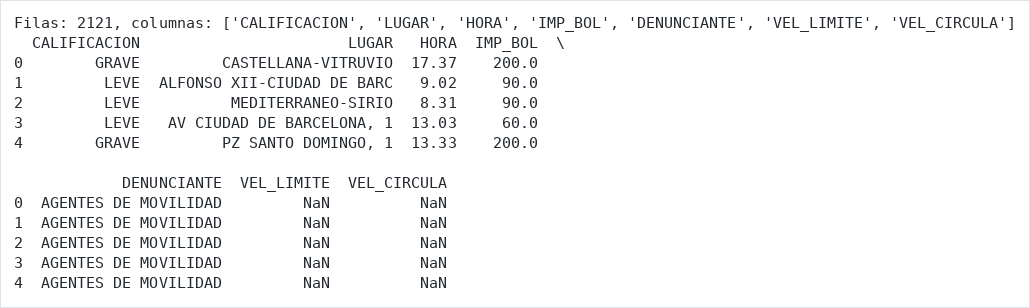

In [7]:
def check_load_dataframe_result():
    df = load_dataframe(TESTDATAFILE)
    print(f'Filas: {len(df)}, columnas: {list(df.columns)}')
    print(df.head())
check_load_dataframe_result()

Filas: 2121, columnas: ['CALIFICACION', 'LUGAR', 'MES', 'ANIO', 'HORA', 'IMP_BOL', 'DESCUENTO', 'PUNTOS', 'DENUNCIANTE', 'HECHO-BOL', 'VEL_LIMITE', 'VEL_CIRCULA', 'COORDENADA-X', 'COORDENADA-Y']
  CALIFICACION                       LUGAR  MES  ANIO   HORA  IMP_BOL  \
0        GRAVE         CASTELLANA-VITRUVIO   11  2023  17.37    200.0   
1         LEVE  ALFONSO XII-CIUDAD DE BARC   11  2023   9.02     90.0   
2         LEVE          MEDITERRANEO-SIRIO   11  2023   8.31     90.0   
3         LEVE   AV CIUDAD DE BARCELONA, 1   11  2023  13.03     60.0   
4        GRAVE         PZ SANTO DOMINGO, 1   11  2023  13.33    200.0   

  DESCUENTO  PUNTOS           DENUNCIANTE  \
0        SI       6  AGENTES DE MOVILIDAD   
1        SI       0  AGENTES DE MOVILIDAD   
2        SI       0  AGENTES DE MOVILIDAD   
3        SI       0  AGENTES DE MOVILIDAD   
4        SI       0  AGENTES DE MOVILIDAD   

                                           HECHO-BOL  VEL_LIMITE  VEL_CIRCULA  \
0  CONDUCIR UT

Comprueba tus doctests

In [8]:
doctest.run_docstring_examples(load_dataframe, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = load_dataframe('data_test.csv')
Expecting nothing
ok
Trying:
    len(df)
Expecting:
    2121
ok
Trying:
    sorted(df['CALIFICACION'].unique())
Expecting:
    ['GRAVE', 'LEVE', 'MUY GRAVE']
ok
Trying:
    df.loc[0, 'LUGAR']
Expecting:
    'CASTELLANA-VITRUVIO'
ok
Trying:
    df['IMP_BOL'].dtype, df['VEL_LIMITE'].dtype, df['VEL_CIRCULA'].dtype
Expecting:
    (dtype('float64'), dtype('float64'), dtype('float64'))
ok
Trying:
    int(df['VEL_CIRCULA'].notna().sum())
Expecting:
    276
ok


Comprueba la calidad del docstring

In [9]:
help(load_dataframe)

Help on function load_dataframe in module __main__:

load_dataframe(filepath: str) -> pandas.DataFrame
    Carga el CSV de multas en un DataFrame con los datos ya limpios.
    
    - Quita los espacios sobrantes de los nombres de columna, así
      'VEL_CIRCULA ' pasa a llamarse 'VEL_CIRCULA' (y ' PUNTOS', 'PUNTOS').
    - Quita los espacios de relleno de CALIFICACION, LUGAR y DENUNCIANTE.
    - Deja IMP_BOL como float.
    - Convierte VEL_LIMITE y VEL_CIRCULA a números, con NaN en las filas
      que no son de velocidad (en el CSV vienen como espacios en blanco).
    
    Args:
        filepath: Ruta del fichero CSV (separado por ';').
    
    Returns:
        pd.DataFrame: Una fila por multa, con todas las columnas del CSV.
    
    Examples:
        >>> df = load_dataframe('data_test.csv')
        >>> len(df)
        2121
        >>> sorted(df['CALIFICACION'].unique())
        ['GRAVE', 'LEVE', 'MUY GRAVE']
        >>> df.loc[0, 'LUGAR']
        'CASTELLANA-VITRUVIO'
        >>> df

### Comprobación automática del código

In [10]:
testing.test_load_dataframe(load_dataframe)

test_load_dataframe OK


In [11]:
testing.test_load_dataframe_typehints(load_dataframe)

check type hints OK


In [12]:
testing.test_docstring(load_dataframe)

docstring OK


In [13]:
testing.test_doctests(load_dataframe, globals())

doctests OK


A partir de aquí reutilizamos `FINES_DF`, calculado con la función que acabas de implementar, en el resto de ejercicios del cuaderno.

In [14]:
FINES_DF = load_dataframe(TESTDATAFILE)
FINES_DF.shape

(2121, 14)

## Ejercicio 2: Importe Medio por Calificación con Pandas

Escribe una función con la cabecera `def average_amount_by_qualification(df: pd.DataFrame) -> pd.Series:` que reciba el `DataFrame` de multas y devuelva una `Series` con el importe medio (`IMP_BOL`) por cada `CALIFICACION`, redondeado a dos decimales y ordenada de mayor a menor importe medio.

In [15]:
# YOUR CODE HERE
def average_amount_by_qualification(df: pd.DataFrame) -> pd.Series:
    """Calcula el importe medio de las multas por calificación.

    Agrupa por CALIFICACION, calcula la media de IMP_BOL, la redondea a dos
    decimales y ordena el resultado de mayor a menor importe medio.

    Args:
        df: DataFrame de multas (ver load_dataframe).

    Returns:
        pd.Series: Importe medio indexado por CALIFICACION, en orden
        descendente.

    Examples:
        >>> df = pd.DataFrame({'CALIFICACION': ['LEVE', 'GRAVE', 'LEVE', 'GRAVE'],
        ...                    'IMP_BOL': [60.0, 200.0, 90.0, 100.0]})
        >>> average_amount_by_qualification(df)
        CALIFICACION
        GRAVE    150.0
        LEVE      75.0
        Name: IMP_BOL, dtype: float64
        >>> average_amount_by_qualification(df).index.tolist()
        ['GRAVE', 'LEVE']
    """
    return (
        df.groupby('CALIFICACION')['IMP_BOL']
        .mean()
        .round(2)
        .sort_values(ascending=False)
    )


In [ ]:
# Escribe aquí tus pruebas

### Auto comprobación

La salida de la siguiente casilla debe mostrar el importe medio por calificación en `FINES_DF`.

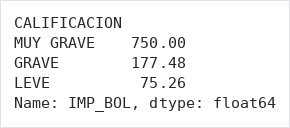

In [16]:
def check_average_amount_by_qualification_result():
    print(average_amount_by_qualification(FINES_DF))
check_average_amount_by_qualification_result()

CALIFICACION
MUY GRAVE    750.00
GRAVE        177.48
LEVE          75.26
Name: IMP_BOL, dtype: float64


Comprueba tus doctests

In [17]:
doctest.run_docstring_examples(average_amount_by_qualification, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = pd.DataFrame({'CALIFICACION': ['LEVE', 'GRAVE', 'LEVE', 'GRAVE'],
                       'IMP_BOL': [60.0, 200.0, 90.0, 100.0]})
Expecting nothing
ok
Trying:
    average_amount_by_qualification(df)
Expecting:
    CALIFICACION
    GRAVE    150.0
    LEVE      75.0
    Name: IMP_BOL, dtype: float64
ok
Trying:
    average_amount_by_qualification(df).index.tolist()
Expecting:
    ['GRAVE', 'LEVE']
ok


Comprueba la calidad del docstring

In [18]:
help(average_amount_by_qualification)

Help on function average_amount_by_qualification in module __main__:

average_amount_by_qualification(df: pandas.DataFrame) -> pandas.Series
    Calcula el importe medio de las multas por calificación.
    
    Agrupa por CALIFICACION, calcula la media de IMP_BOL, la redondea a dos
    decimales y ordena el resultado de mayor a menor importe medio.
    
    Args:
        df: DataFrame de multas (ver load_dataframe).
    
    Returns:
        pd.Series: Importe medio indexado por CALIFICACION, en orden
        descendente.
    
    Examples:
        >>> df = pd.DataFrame({'CALIFICACION': ['LEVE', 'GRAVE', 'LEVE', 'GRAVE'],
        ...                    'IMP_BOL': [60.0, 200.0, 90.0, 100.0]})
        >>> average_amount_by_qualification(df)
        CALIFICACION
        GRAVE    150.0
        LEVE      75.0
        Name: IMP_BOL, dtype: float64
        >>> average_amount_by_qualification(df).index.tolist()
        ['GRAVE', 'LEVE']



### Comprobación automática del código

In [19]:
testing.test_average_amount_by_qualification(average_amount_by_qualification, FINES_DF)

test_average_amount_by_qualification OK


In [20]:
testing.test_average_amount_by_qualification_typehints(average_amount_by_qualification)

check type hints OK


In [21]:
testing.test_docstring(average_amount_by_qualification)

docstring OK


In [22]:
testing.test_doctests(average_amount_by_qualification, globals())

doctests OK


## Ejercicio 3: Lugares con Más Multas con Pandas

Escribe una función con la cabecera `def top_n_locations(df: pd.DataFrame, n: int) -> pd.DataFrame:` que reciba el `DataFrame` de multas y un número `n`, y devuelva un `DataFrame` de dos columnas, `'LUGAR'` y `'count'`, con los `n` lugares (`LUGAR`) con más multas, ordenados de mayor a menor número de multas.

In [23]:
# YOUR CODE HERE
def top_n_locations(df: pd.DataFrame, n: int) -> pd.DataFrame:
    """Devuelve los n lugares con más multas.

    Cuenta las multas de cada LUGAR con value_counts (que ya ordena de
    mayor a menor) y se queda con las n primeras.

    Args:
        df: DataFrame de multas (ver load_dataframe).
        n: Número de lugares a devolver.

    Returns:
        pd.DataFrame: Dos columnas, 'LUGAR' y 'count', ordenadas de mayor a
        menor número de multas, con índice 0..n-1.

    Examples:
        >>> df = pd.DataFrame({'LUGAR': ['GRAN VIA', 'ALCALA', 'GRAN VIA',
        ...                              'ATOCHA', 'GRAN VIA', 'ALCALA']})
        >>> top_n_locations(df, 2)
              LUGAR  count
        0  GRAN VIA      3
        1    ALCALA      2
        >>> list(top_n_locations(df, 2).columns)
        ['LUGAR', 'count']
        >>> len(top_n_locations(df, 10))
        3
    """
    counts = df['LUGAR'].value_counts().head(n)
    return counts.rename_axis('LUGAR').reset_index(name='count')


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar los 5 lugares con más multas en `FINES_DF`.

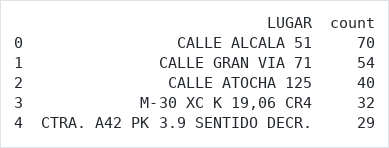

In [24]:
def check_top_n_locations_result():
    print(top_n_locations(FINES_DF, 5))
check_top_n_locations_result()

                            LUGAR  count
0                 CALLE ALCALA 51     70
1               CALLE GRAN VIA 71     54
2                CALLE ATOCHA 125     40
3             M-30 XC K 19,06 CR4     32
4  CTRA. A42 PK 3.9 SENTIDO DECR.     29


Comprueba tus doctests

In [25]:
doctest.run_docstring_examples(top_n_locations, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = pd.DataFrame({'LUGAR': ['GRAN VIA', 'ALCALA', 'GRAN VIA',
                                 'ATOCHA', 'GRAN VIA', 'ALCALA']})
Expecting nothing
ok
Trying:
    top_n_locations(df, 2)
Expecting:
          LUGAR  count
    0  GRAN VIA      3
    1    ALCALA      2
ok
Trying:
    list(top_n_locations(df, 2).columns)
Expecting:
    ['LUGAR', 'count']
ok
Trying:
    len(top_n_locations(df, 10))
Expecting:
    3
ok


Comprueba la calidad del docstring

In [26]:
help(top_n_locations)

Help on function top_n_locations in module __main__:

top_n_locations(df: pandas.DataFrame, n: int) -> pandas.DataFrame
    Devuelve los n lugares con más multas.
    
    Cuenta las multas de cada LUGAR con value_counts (que ya ordena de
    mayor a menor) y se queda con las n primeras.
    
    Args:
        df: DataFrame de multas (ver load_dataframe).
        n: Número de lugares a devolver.
    
    Returns:
        pd.DataFrame: Dos columnas, 'LUGAR' y 'count', ordenadas de mayor a
        menor número de multas, con índice 0..n-1.
    
    Examples:
        >>> df = pd.DataFrame({'LUGAR': ['GRAN VIA', 'ALCALA', 'GRAN VIA',
        ...                              'ATOCHA', 'GRAN VIA', 'ALCALA']})
        >>> top_n_locations(df, 2)
              LUGAR  count
        0  GRAN VIA      3
        1    ALCALA      2
        >>> list(top_n_locations(df, 2).columns)
        ['LUGAR', 'count']
        >>> len(top_n_locations(df, 10))
        3



### Comprobación automática del código

In [27]:
testing.test_top_n_locations(top_n_locations, FINES_DF)

test_top_n_locations OK


In [28]:
testing.test_top_n_locations_typehints(top_n_locations)

check type hints OK


In [29]:
testing.test_docstring(top_n_locations)

docstring OK


In [30]:
testing.test_doctests(top_n_locations, globals())

doctests OK


## Ejercicio 4: Categorización de Importes con `pd.cut`

Escribe una función con la cabecera `def add_amount_category(df: pd.DataFrame) -> pd.DataFrame:` que reciba el `DataFrame` de multas y devuelva **una copia** con una nueva columna `'CATEGORIA_IMPORTE'`, calculada con `pd.cut` sobre `IMP_BOL`:
- `'BAJO'` si el importe es menor o igual que 100
- `'MEDIO'` si el importe está entre 100 (exclusivo) y 200 (inclusive)
- `'ALTO'` si el importe es mayor que 200

**Importante:** la función no debe modificar el `DataFrame` que recibe como argumento; trabaja sobre una copia (`df.copy()`).

In [33]:
def add_amount_category(df: pd.DataFrame) -> pd.DataFrame:
    """Añade la columna CATEGORIA_IMPORTE según el importe de la multa.

    Usa pd.cut sobre IMP_BOL con intervalos cerrados por la derecha:
    (-inf, 100] -> 'BAJO', (100, 200] -> 'MEDIO' y (200, inf) -> 'ALTO'.
    Trabaja sobre una copia, así que el DataFrame original no se modifica.

    Args:
        df: DataFrame de multas con la columna IMP_BOL.

    Returns:
        pd.DataFrame: Copia de df con la columna nueva CATEGORIA_IMPORTE.

    Examples:
        >>> df = pd.DataFrame({'IMP_BOL': [60.0, 100.0, 100.5, 200.0, 500.0]})
        >>> add_amount_category(df)['CATEGORIA_IMPORTE'].tolist()
        ['BAJO', 'BAJO', 'MEDIO', 'MEDIO', 'ALTO']
        >>> 'CATEGORIA_IMPORTE' in df.columns
        False
    """
    result = df.copy()
    result['CATEGORIA_IMPORTE'] = pd.cut(
        result['IMP_BOL'], bins=AMOUNT_BINS, labels=AMOUNT_LABELS, right=True
    )
    return result


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar cuántas multas de `FINES_DF` caen en cada categoría de importe.

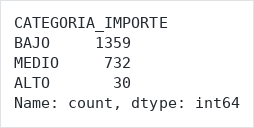

In [34]:
def check_add_amount_category_result():
    result = add_amount_category(FINES_DF)
    print(result['CATEGORIA_IMPORTE'].value_counts())
check_add_amount_category_result()

CATEGORIA_IMPORTE
BAJO     1359
MEDIO     732
ALTO       30
Name: count, dtype: int64


Comprueba tus doctests

In [35]:
doctest.run_docstring_examples(add_amount_category, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = pd.DataFrame({'IMP_BOL': [60.0, 100.0, 100.5, 200.0, 500.0]})
Expecting nothing
ok
Trying:
    add_amount_category(df)['CATEGORIA_IMPORTE'].tolist()
Expecting:
    ['BAJO', 'BAJO', 'MEDIO', 'MEDIO', 'ALTO']
ok
Trying:
    'CATEGORIA_IMPORTE' in df.columns
Expecting:
    False
ok


Comprueba la calidad del docstring

In [36]:
help(add_amount_category)

Help on function add_amount_category in module __main__:

add_amount_category(df: pandas.DataFrame) -> pandas.DataFrame
    Añade la columna CATEGORIA_IMPORTE según el importe de la multa.
    
    Usa pd.cut sobre IMP_BOL con intervalos cerrados por la derecha:
    (-inf, 100] -> 'BAJO', (100, 200] -> 'MEDIO' y (200, inf) -> 'ALTO'.
    Trabaja sobre una copia, así que el DataFrame original no se modifica.
    
    Args:
        df: DataFrame de multas con la columna IMP_BOL.
    
    Returns:
        pd.DataFrame: Copia de df con la columna nueva CATEGORIA_IMPORTE.
    
    Examples:
        >>> df = pd.DataFrame({'IMP_BOL': [60.0, 100.0, 100.5, 200.0, 500.0]})
        >>> add_amount_category(df)['CATEGORIA_IMPORTE'].tolist()
        ['BAJO', 'BAJO', 'MEDIO', 'MEDIO', 'ALTO']
        >>> 'CATEGORIA_IMPORTE' in df.columns
        False



### Comprobación automática del código

In [37]:
testing.test_add_amount_category(add_amount_category, FINES_DF)

test_add_amount_category OK


In [38]:
testing.test_add_amount_category_typehints(add_amount_category)

check type hints OK


In [39]:
testing.test_docstring(add_amount_category)

docstring OK


In [40]:
testing.test_doctests(add_amount_category, globals())

doctests OK


## Ejercicio 5: Exceso de Velocidad por Lugar con Pandas

Algunas multas (las de exceso de velocidad) tienen registrados `VEL_LIMITE` y `VEL_CIRCULA`. Escribe una función con la cabecera `def speed_excess_by_location(df: pd.DataFrame, n: int) -> pd.DataFrame:` que:
1. Se quede solo con las filas donde `VEL_LIMITE` y `VEL_CIRCULA` tienen valor (usa `dropna`).
2. Calcule el exceso de velocidad de cada una de esas filas como `VEL_CIRCULA - VEL_LIMITE`.
3. Agrupe por `LUGAR` y calcule el exceso medio, redondeado a dos decimales.
4. Devuelva un `DataFrame` de dos columnas, `'LUGAR'` y `'EXCESO_MEDIO'`, con los `n` lugares de mayor exceso medio, ordenados de mayor a menor.

In [41]:
def speed_excess_by_location(df: pd.DataFrame, n: int) -> pd.DataFrame:
    """Devuelve los n lugares con mayor exceso medio de velocidad.

    Se queda solo con las multas que tienen VEL_LIMITE y VEL_CIRCULA,
    calcula el exceso (VEL_CIRCULA - VEL_LIMITE), lo promedia por LUGAR
    redondeando a dos decimales y devuelve los n lugares con mayor exceso
    medio, de mayor a menor.

    Args:
        df: DataFrame de multas (ver load_dataframe).
        n: Número de lugares a devolver.

    Returns:
        pd.DataFrame: Dos columnas, 'LUGAR' y 'EXCESO_MEDIO', con índice
        0..n-1.

    Examples:
        >>> df = pd.DataFrame({
        ...     'LUGAR':       ['M-30', 'M-30', 'A-6', 'GRAN VIA', 'A-6'],
        ...     'VEL_LIMITE':  [70.0,   70.0,   90.0,  None,       90.0],
        ...     'VEL_CIRCULA': [90.0,   80.0,   120.0, None,       None]})
        >>> speed_excess_by_location(df, 2)
          LUGAR  EXCESO_MEDIO
        0   A-6          30.0
        1  M-30          15.0
        >>> speed_excess_by_location(df, 5)['LUGAR'].tolist()
        ['A-6', 'M-30']
    """
    speeding = df.dropna(subset=['VEL_LIMITE', 'VEL_CIRCULA']).copy()
    speeding['EXCESO'] = speeding['VEL_CIRCULA'] - speeding['VEL_LIMITE']
    excess = (
        speeding.groupby('LUGAR')['EXCESO']
        .mean()
        .round(2)
        .sort_values(ascending=False)
        .head(n)
    )
    return excess.rename_axis('LUGAR').reset_index(name='EXCESO_MEDIO')


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar los 5 lugares con mayor exceso medio de velocidad en `FINES_DF`.

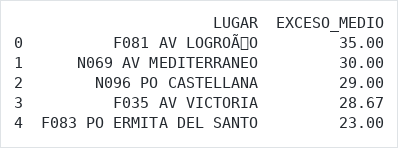

In [42]:
def check_speed_excess_by_location_result():
    print(speed_excess_by_location(FINES_DF, 5))
check_speed_excess_by_location_result()

                      LUGAR  EXCESO_MEDIO
0           F081 AV LOGROÑO         35.00
1      N069 AV MEDITERRANEO         30.00
2        N096 PO CASTELLANA         29.00
3          F035 AV VICTORIA         28.67
4  F083 PO ERMITA DEL SANTO         23.00


Comprueba tus doctests

In [43]:
doctest.run_docstring_examples(speed_excess_by_location, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = pd.DataFrame({
        'LUGAR':       ['M-30', 'M-30', 'A-6', 'GRAN VIA', 'A-6'],
        'VEL_LIMITE':  [70.0,   70.0,   90.0,  None,       90.0],
        'VEL_CIRCULA': [90.0,   80.0,   120.0, None,       None]})
Expecting nothing
ok
Trying:
    speed_excess_by_location(df, 2)
Expecting:
      LUGAR  EXCESO_MEDIO
    0   A-6          30.0
    1  M-30          15.0
ok
Trying:
    speed_excess_by_location(df, 5)['LUGAR'].tolist()
Expecting:
    ['A-6', 'M-30']
ok


Comprueba la calidad del docstring

In [44]:
help(speed_excess_by_location)

Help on function speed_excess_by_location in module __main__:

speed_excess_by_location(df: pandas.DataFrame, n: int) -> pandas.DataFrame
    Devuelve los n lugares con mayor exceso medio de velocidad.
    
    Se queda solo con las multas que tienen VEL_LIMITE y VEL_CIRCULA,
    calcula el exceso (VEL_CIRCULA - VEL_LIMITE), lo promedia por LUGAR
    redondeando a dos decimales y devuelve los n lugares con mayor exceso
    medio, de mayor a menor.
    
    Args:
        df: DataFrame de multas (ver load_dataframe).
        n: Número de lugares a devolver.
    
    Returns:
        pd.DataFrame: Dos columnas, 'LUGAR' y 'EXCESO_MEDIO', con índice
        0..n-1.
    
    Examples:
        >>> df = pd.DataFrame({
        ...     'LUGAR':       ['M-30', 'M-30', 'A-6', 'GRAN VIA', 'A-6'],
        ...     'VEL_LIMITE':  [70.0,   70.0,   90.0,  None,       90.0],
        ...     'VEL_CIRCULA': [90.0,   80.0,   120.0, None,       None]})
        >>> speed_excess_by_location(df, 2)
          LU

### Comprobación automática del código

In [45]:
testing.test_speed_excess_by_location(speed_excess_by_location, FINES_DF)

test_speed_excess_by_location OK


In [46]:
testing.test_speed_excess_by_location_typehints(speed_excess_by_location)

check type hints OK


In [47]:
testing.test_docstring(speed_excess_by_location)

docstring OK


In [48]:
testing.test_doctests(speed_excess_by_location, globals())

doctests OK


## Ejercicio 6: Tabla Dinámica de Calificación por Denunciante

Escribe una función con la cabecera `def qualification_by_complainant_pivot(df: pd.DataFrame) -> pd.DataFrame:` que reciba el `DataFrame` de multas y devuelva una tabla dinámica (usa `pd.pivot_table`) con `CALIFICACION` como filas, `DENUNCIANTE` como columnas, y el número de multas de cada combinación como valores. Las combinaciones sin ninguna multa deben aparecer como `0` (no como `NaN`).

In [49]:
def qualification_by_complainant_pivot(df: pd.DataFrame) -> pd.DataFrame:
    """Cuenta las multas de cada combinación calificación-denunciante.

    Construye una tabla dinámica con CALIFICACION como filas, DENUNCIANTE
    como columnas y el número de multas como valores. Las combinaciones
    sin multas aparecen como 0 en lugar de NaN.

    Args:
        df: DataFrame de multas (ver load_dataframe).

    Returns:
        pd.DataFrame: Tabla de recuentos (enteros), con una fila por
        calificación y una columna por denunciante.

    Examples:
        >>> df = pd.DataFrame({
        ...     'CALIFICACION': ['GRAVE', 'LEVE', 'GRAVE', 'LEVE'],
        ...     'DENUNCIANTE':  ['SER',   'SER',  'SER',   'POLICIA'],
        ...     'IMP_BOL':      [200.0,   90.0,   200.0,   60.0]})
        >>> pivot = qualification_by_complainant_pivot(df)
        >>> int(pivot.loc['GRAVE', 'SER']), int(pivot.loc['LEVE', 'POLICIA'])
        (2, 1)
        >>> int(pivot.loc['GRAVE', 'POLICIA'])
        0
        >>> bool(pivot.isna().values.any())
        False
    """
    return pd.pivot_table(
        df,
        index='CALIFICACION',
        columns='DENUNCIANTE',
        values='IMP_BOL',
        aggfunc='count',
        fill_value=0,
    )


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar la tabla dinámica de calificación por denunciante en `FINES_DF`.

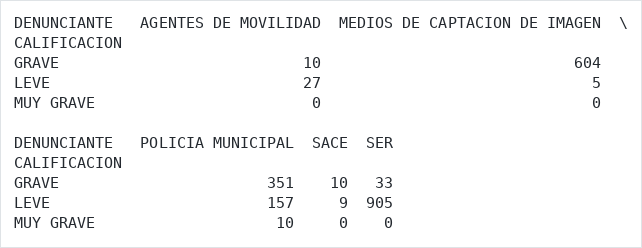

In [50]:
def check_qualification_by_complainant_pivot_result():
    print(qualification_by_complainant_pivot(FINES_DF))
check_qualification_by_complainant_pivot_result()

DENUNCIANTE   AGENTES DE MOVILIDAD  MEDIOS DE CAPTACION DE IMAGEN  \
CALIFICACION                                                        
GRAVE                           10                            604   
LEVE                            27                              5   
MUY GRAVE                        0                              0   

DENUNCIANTE   POLICIA MUNICIPAL  SACE  SER  
CALIFICACION                                
GRAVE                       351    10   33  
LEVE                        157     9  905  
MUY GRAVE                    10     0    0  


Comprueba tus doctests

In [51]:
doctest.run_docstring_examples(qualification_by_complainant_pivot, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = pd.DataFrame({
        'CALIFICACION': ['GRAVE', 'LEVE', 'GRAVE', 'LEVE'],
        'DENUNCIANTE':  ['SER',   'SER',  'SER',   'POLICIA'],
        'IMP_BOL':      [200.0,   90.0,   200.0,   60.0]})
Expecting nothing
ok
Trying:
    pivot = qualification_by_complainant_pivot(df)
Expecting nothing
ok
Trying:
    int(pivot.loc['GRAVE', 'SER']), int(pivot.loc['LEVE', 'POLICIA'])
Expecting:
    (2, 1)
ok
Trying:
    int(pivot.loc['GRAVE', 'POLICIA'])
Expecting:
    0
ok
Trying:
    bool(pivot.isna().values.any())
Expecting:
    False
ok


Comprueba la calidad del docstring

In [52]:
help(qualification_by_complainant_pivot)

Help on function qualification_by_complainant_pivot in module __main__:

qualification_by_complainant_pivot(df: pandas.DataFrame) -> pandas.DataFrame
    Cuenta las multas de cada combinación calificación-denunciante.
    
    Construye una tabla dinámica con CALIFICACION como filas, DENUNCIANTE
    como columnas y el número de multas como valores. Las combinaciones
    sin multas aparecen como 0 en lugar de NaN.
    
    Args:
        df: DataFrame de multas (ver load_dataframe).
    
    Returns:
        pd.DataFrame: Tabla de recuentos (enteros), con una fila por
        calificación y una columna por denunciante.
    
    Examples:
        >>> df = pd.DataFrame({
        ...     'CALIFICACION': ['GRAVE', 'LEVE', 'GRAVE', 'LEVE'],
        ...     'DENUNCIANTE':  ['SER',   'SER',  'SER',   'POLICIA'],
        ...     'IMP_BOL':      [200.0,   90.0,   200.0,   60.0]})
        >>> pivot = qualification_by_complainant_pivot(df)
        >>> int(pivot.loc['GRAVE', 'SER']), int(pivot.loc['

### Comprobación automática del código

In [53]:
testing.test_qualification_by_complainant_pivot(qualification_by_complainant_pivot, FINES_DF)

test_qualification_by_complainant_pivot OK


In [54]:
testing.test_qualification_by_complainant_pivot_typehints(qualification_by_complainant_pivot)

check type hints OK


In [55]:
testing.test_docstring(qualification_by_complainant_pivot)

docstring OK


In [56]:
testing.test_doctests(qualification_by_complainant_pivot, globals())

doctests OK


## Ejercicio 7: Gráfico de Multas por Calificación con Matplotlib

Escribe una función con la cabecera `def plot_fines_by_qualification(df: pd.DataFrame) -> None:` que reciba el `DataFrame` de multas y muestre un diagrama de barras con el número de multas de cada `CALIFICACION`. El gráfico debe tener título y etiquetas en los ejes, coo el que sigue:

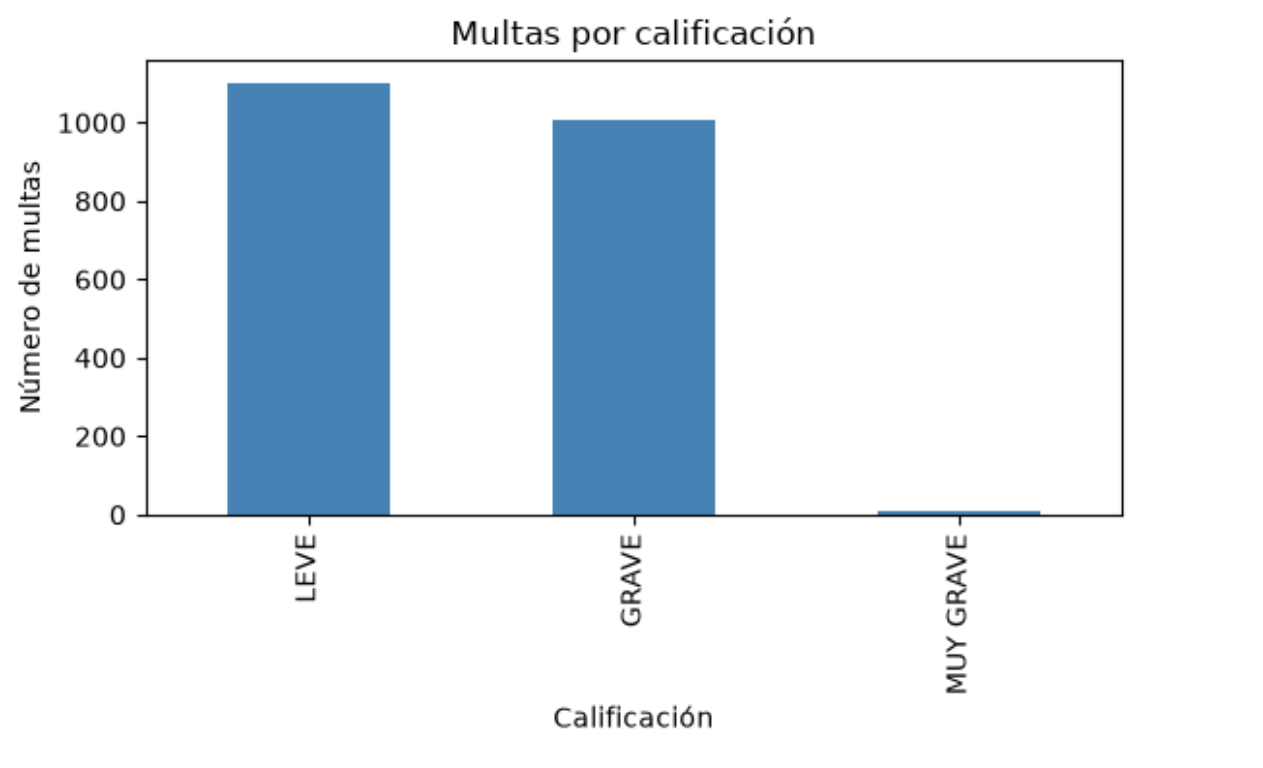

**Este ejercicio se corrige de forma manual** (4 puntos). Asegúrate de que la celda de la solución, al ejecutarla, muestra el gráfico terminado (llama a tu función al final de la misma celda, usando `FINES_DF`).

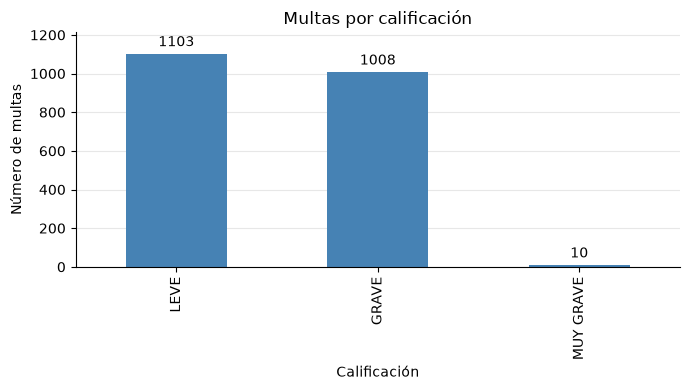

In [60]:
def plot_fines_by_qualification(df: pd.DataFrame) -> None:
    """Muestra un diagrama de barras con el número de multas por calificación.

    Cuenta las multas de cada CALIFICACION con value_counts (de mayor a
    menor) y las dibuja como barras, con título y etiquetas en los ejes.

    Args:
        df: DataFrame de multas con la columna CALIFICACION.

    Returns:
        None. Muestra el gráfico.
    """
    counts = df['CALIFICACION'].value_counts()

    fig, ax = plt.subplots(figsize=(7, 4))
    counts.plot(kind='bar', ax=ax, color='steelblue', width=0.5)
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(y=0.1)

    ax.set_title('Multas por calificación')
    ax.set_xlabel('Calificación')
    ax.set_ylabel('Número de multas')
    ax.tick_params(axis='x', labelrotation=90)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

    fig.tight_layout()
    plt.show()


plot_fines_by_qualification(FINES_DF)


**Criterios de corrección manual:**
- La función usa `FINES_DF['CALIFICACION']` (o equivalente) para contar las multas por calificación.
- El gráfico es un diagrama de barras (u otro tipo apropiado para datos categóricos).
- Tiene título y etiquetas en ambos ejes.
- Los datos representados son correctos (GRAVE, LEVE y MUY GRAVE con sus recuentos).

## Ejercicio 8: Gráfico de Multas por Hora con Matplotlib

Escribe una función con la cabecera `def plot_fines_by_hour(df: pd.DataFrame) -> None:` que reciba el `DataFrame` de multas y muestre un gráfico de líneas con el número de multas registradas en cada hora del día (0 a 23). Recuerda que la columna `HORA` es un valor como `17.37`, donde la parte entera es la hora. El gráfico debe tener título y etiquetas en los ejes, como el que sigue:

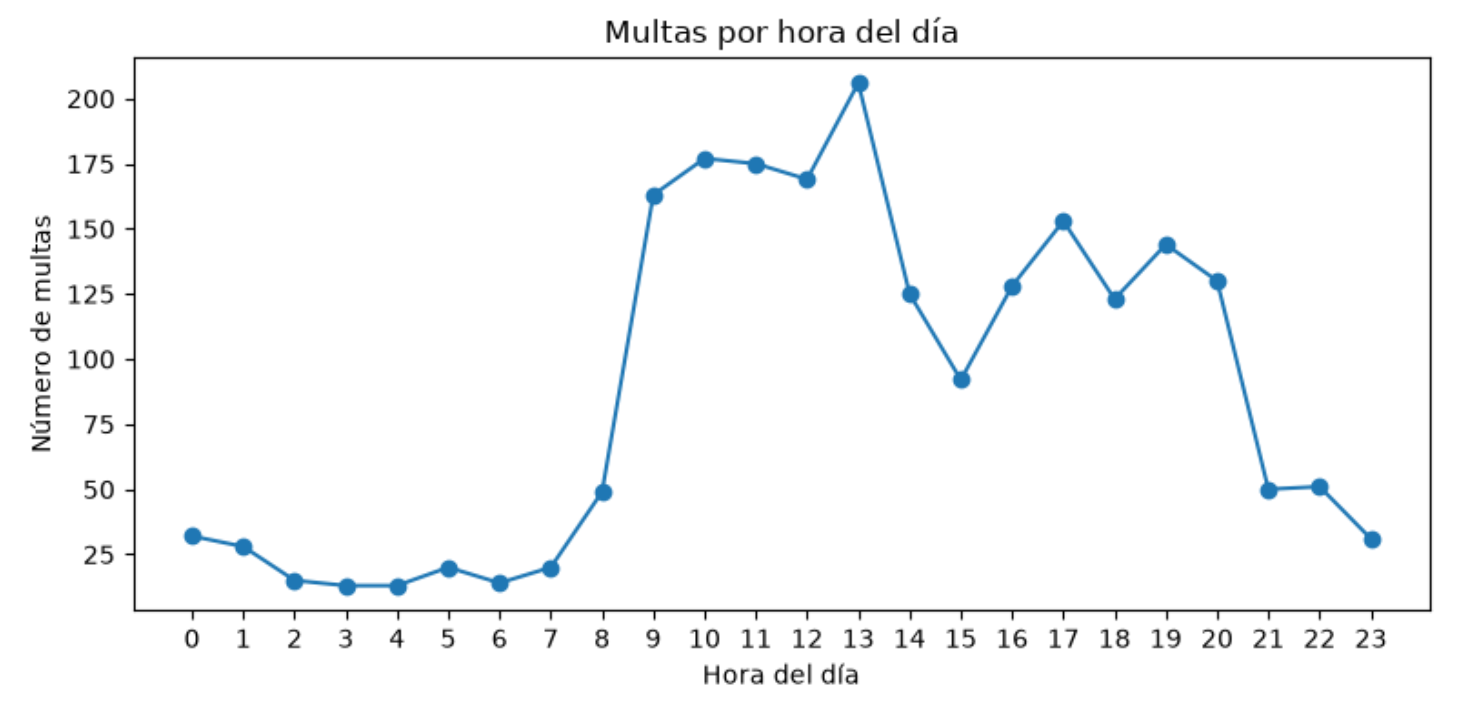

**Este ejercicio se corrige de forma manual** (4 puntos). Asegúrate de que la celda de la solución, al ejecutarla, muestra el gráfico terminado (llama a tu función al final de la misma celda, usando `FINES_DF`).

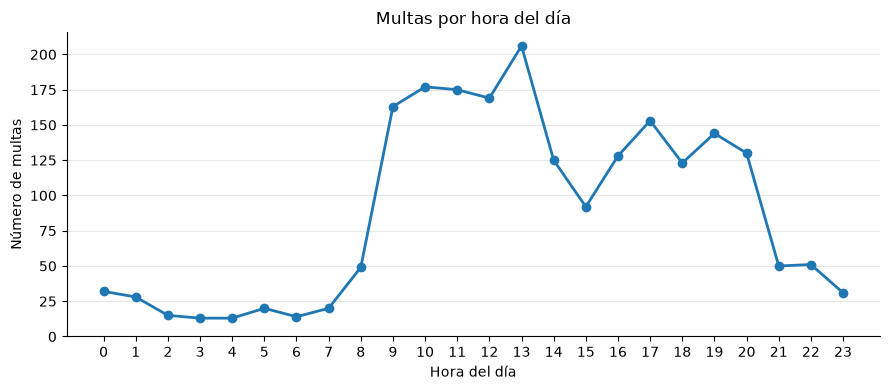

In [61]:
def plot_fines_by_hour(df: pd.DataFrame) -> None:
    """Muestra un gráfico de líneas con el número de multas por hora del día.

    La hora es la parte entera de la columna HORA (17.37 -> 17). Se cuentan
    las multas de cada hora y se reindexa de 0 a 23, para que las horas sin
    multas aparezcan con 0 y estén representadas las 24 horas.

    Args:
        df: DataFrame de multas con la columna HORA.

    Returns:
        None. Muestra el gráfico.
    """
    hours = df['HORA'].astype(int)
    counts = hours.value_counts().reindex(range(24), fill_value=0)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(counts.index, counts.values, marker='o', color='tab:blue', linewidth=2)

    ax.set_title('Multas por hora del día')
    ax.set_xlabel('Hora del día')
    ax.set_ylabel('Número de multas')
    ax.set_xticks(range(24))
    ax.set_ylim(bottom=0)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)

    fig.tight_layout()
    plt.show()


plot_fines_by_hour(FINES_DF)


**Criterios de corrección manual:**
- Se extrae correctamente la hora (parte entera) de la columna `HORA`.
- El gráfico es de tipo línea (u otro apropiado para una serie temporal/ordinal como la hora del día).
- Tiene título y etiquetas en ambos ejes, con las 24 horas representadas.
- Los datos representados son correctos (coinciden con el recuento de multas por hora en `FINES_DF`).

## Comprobación final antes de entregar

**Guarda el cuaderno ahora (Ctrl+S / Cmd+S)** y, después, ejecuta la siguiente casilla. Comprueba que no haya identificadores de celda duplicados (algo que suele pasar al copiar una celda de solución o de test en vez de escribir en la tuya propia).

In [62]:
testing.check_duplicated_ids('E3_pandas.ipynb')

OK. No se han encontrado grade_id duplicados.
